# Module 7: Unsupervised Learning Algorithms: hands-on lab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/prajwalskandas31-sudo/ai-engineering-course/blob/main/module-07-unsupervised-learning/Module_7_Lab.ipynb)

Part of the free **AI Engineering Course** by Tech with Prajwal. ▶️ [Module 7 videos](https://www.youtube.com/playlist?list=PLEYTSV2T81_0) · 📒 [Study notes (Notion)](https://chipped-willow-4a2.notion.site/41e6f1ed006e8106a164fa3c0390fa5b) · 💻 [Module 7 on GitHub](https://github.com/prajwalskandas31-sudo/ai-engineering-course/tree/main/module-07-unsupervised-learning)

**How to use:** run the cells from top to bottom (**Runtime → Run all**), or one at a time with **Shift + Enter**. Everything this lab needs is already installed in Google Colab. Change the numbers and re-run to experiment.

## customer_segmentation_lesson.py

Module 7: Unsupervised Learning Algorithms — Practical Lesson
Scenario: Customer Behavioral Segmentation & Outlier Detection

This beginner-friendly Python program demonstrates how to apply all four 
unsupervised learning algorithms covered in Module 7 using scikit-learn:

1. Principal Component Analysis (PCA) - Dimensionality Reduction & Visualization
2. K-Means Clustering - Centroid-based Customer Personas
3. Hierarchical Agglomerative Clustering - Hierarchical Taxonomy & Dendrograms
4. DBSCAN - Density-based Clustering & Fraud/Outlier Detection

Prerequisites: Python 3.x, pandas, numpy, scikit-learn, matplotlib, scipy

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score

### Set random seed for reproducible synthetic customer dataset

In [2]:
# Set random seed for reproducible synthetic customer dataset
np.random.seed(42)

### `generate_customer_data()`: Generates synthetic e-commerce customer data with 5 behavioral features:

In [3]:
def generate_customer_data(n_samples=300):
    """
    Generates synthetic e-commerce customer data with 5 behavioral features:
    1. Annual Income (in $1,000s)
    2. Spending Score (1-100)
    3. Purchase Frequency (orders/year)
    4. Return Rate (percentage)
    5. Session Duration (minutes/visit)
    """
    print("[Step 1] Generating synthetic e-commerce customer dataset...")
    
    # Generate 3 natural clusters + random noise/outliers
    cluster_1 = np.random.normal(loc=[30, 20, 10, 5, 12], scale=[5, 5, 3, 2, 3], size=(100, 5))
    cluster_2 = np.random.normal(loc=[85, 80, 45, 8, 35], scale=[8, 6, 5, 2, 5], size=(100, 5))
    cluster_3 = np.random.normal(loc=[90, 25, 15, 12, 18], scale=[7, 5, 4, 3, 4], size=(90, 5))
    
    # Anomalous customers (Outliers / Fraudulent behavior)
    outliers = np.array([
        [150, 95, 120, 75, 120],  # High return, extreme purchases
        [15, 95, 5, 90, 2],       # Extreme return rate
        [200, 10, 1, 1, 150],     # Extremely high income, rare visits
        [10, 10, 1, 95, 1],
        [130, 85, 90, 80, 90],
        [40, 90, 80, 10, 60],
        [110, 15, 5, 50, 5],
        [25, 85, 50, 5, 45],
        [70, 50, 25, 15, 25],
        [65, 55, 22, 10, 20]
    ])
    
    data = np.vstack([cluster_1, cluster_2, cluster_3, outliers])
    columns = [
        'Annual_Income_k', 'Spending_Score', 
        'Purchase_Freq', 'Return_Rate_Pct', 'Session_Duration_Min'
    ]
    
    df = pd.DataFrame(data, columns=columns)
    print(f"Dataset created successfully: {df.shape[0]} customers, {df.shape[1]} features.\n")
    return df

### `preprocess_data()`: Standardizes features to zero mean and unit variance.

In [4]:
def preprocess_data(df):
    """
    Standardizes features to zero mean and unit variance.
    Unsupervised distance calculations (Euclidean) are sensitive to feature scales.
    """
    print("[Step 2] Standardizing features using StandardScaler...")
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df)
    return X_scaled

### `run_pca()`: Applies Principal Component Analysis (PCA) to reduce 5D metrics to 2D.

In [5]:
def run_pca(X_scaled):
    """
    Applies Principal Component Analysis (PCA) to reduce 5D metrics to 2D.
    Calculates variance explained and displays loading scores.
    """
    print("\n" + "="*60)
    print("1. PRINCIPAL COMPONENT ANALYSIS (PCA)")
    print("="*60)
    
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_scaled)
    
    var_ratio = pca.explained_variance_ratio_
    print(f"Variance explained by PC1: {var_ratio[0]*100:.2f}%")
    print(f"Variance explained by PC2: {var_ratio[1]*100:.2f}%")
    print(f"Total variance retained in 2D projection: {sum(var_ratio)*100:.2f}%")
    
    # Display loading scores (feature contributions to PC1 and PC2)
    loadings = pd.DataFrame(
        pca.components_.T, 
        columns=['PC1_Loading', 'PC2_Loading'], 
        index=['Income', 'Spending', 'Frequency', 'Return_Rate', 'Duration']
    )
    print("\nPCA Loading Scores (Feature Weights):")
    print(loadings.round(3))
    
    return X_pca, pca

### `run_kmeans()`: Executes K-Means Clustering and evaluates the Elbow Method to find optimal K.

In [6]:
def run_kmeans(X_scaled, max_k=8):
    """
    Executes K-Means Clustering and evaluates the Elbow Method to find optimal K.
    """
    print("\n" + "="*60)
    print("2. K-MEANS CLUSTERING & ELBOW METHOD")
    print("="*60)
    
    inertias = []
    k_range = range(1, max_k + 1)
    
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X_scaled)
        inertias.append(kmeans.inertia_)
        print(f"K = {k} | Within-Cluster Sum of Squares (Inertia): {kmeans.inertia_:.2f}")
    
    # Note: on this data the elbow is soft. Inertia keeps falling after K=3 because
    # the 10 outliers can form tiny clusters of their own. K=3 matches the three
    # customer personas we expect from the business, so we choose it on that basis.
    optimal_k = 3
    kmeans_opt = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
    kmeans_labels = kmeans_opt.fit_predict(X_scaled)
    
    return k_range, inertias, kmeans_labels

### `run_hierarchical()`: Executes Agglomerative Hierarchical Clustering.

In [7]:
def run_hierarchical(X_scaled):
    """
    Executes Agglomerative Hierarchical Clustering.
    """
    print("\n" + "="*60)
    print("3. HIERARCHICAL CLUSTERING")
    print("="*60)
    
    # Compute linkage matrix using Ward's distance
    linked = linkage(X_scaled, method='ward')
    
    # Fit Agglomerative Clustering model
    hc = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
    hc_labels = hc.fit_predict(X_scaled)
    print(f"Agglomerative Clustering fitted with 3 main clusters.")
    
    return linked, hc_labels

### `run_dbscan()`: Executes DBSCAN Density-Based Clustering for outlier and non-spherical detection.

In [8]:
def run_dbscan(X_scaled, eps=0.8, min_samples=5):
    """
    Executes DBSCAN Density-Based Clustering for outlier and non-spherical detection.
    """
    print("\n" + "="*60)
    print("4. DBSCAN DENSITY-BASED CLUSTERING")
    print("="*60)
    
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    dbscan_labels = dbscan.fit_predict(X_scaled)
    
    n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    n_noise = list(dbscan_labels).count(-1)
    
    print(f"DBSCAN Hyperparameters: Epsilon = {eps}, MinSamples = {min_samples}")
    print(f"Clusters Discovered: {n_clusters}")
    print(f"Outliers / Noise Points Identified: {n_noise} customers")
    
    return dbscan_labels

### `compare_methods()`: Summarises what each algorithm found.

In [9]:
def compare_methods(df, kmeans_labels, hc_labels, dbscan_labels):
    """
    Summarises what each algorithm found.
    """
    print("\n" + "="*60)
    print("5. WHAT DID EACH METHOD FIND?")
    print("="*60)

    # Persona profiles from K-Means (average raw values per cluster)
    profile = df.groupby(kmeans_labels).mean().round(1)
    profile["Customers"] = pd.Series(kmeans_labels).value_counts().sort_index()
    print("K-Means persona profiles (average values per cluster):")
    with pd.option_context("display.width", 140, "display.max_columns", None):
        print(profile)

    # How closely do K-Means and Hierarchical agree? (1.0 = identical groupings)
    agreement = adjusted_rand_score(kmeans_labels, hc_labels)
    print(f"\nAgreement between K-Means and Hierarchical (Adjusted Rand Index): {agreement:.3f}")

    # Which customers did DBSCAN flag as noise?
    noise_idx = np.where(dbscan_labels == -1)[0]
    print(f"\nDBSCAN flagged {len(noise_idx)} customers as outliers (rows {noise_idx.tolist()}).")
    print("The last 10 rows (290-299) are the planted anomalous customers.")
    print("K-Means and Hierarchical have no 'noise' label, so they force those 10 outliers")
    print("into one of the 3 personas. Only DBSCAN can leave them out.")

### `plot_all_results()`: Generates a master 2x2 visualization panel comparing all algorithms.

In [10]:
def plot_all_results(X_pca, k_range, inertias, kmeans_labels, linked, hc_labels, dbscan_labels):
    """
    Generates a master 2x2 visualization panel comparing all algorithms.
    """
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # 1. K-Means Elbow Curve
    axes[0, 0].plot(k_range, inertias, 'o-', color='#1f77b4', linewidth=2.5, markersize=8)
    axes[0, 0].axvline(x=3, color='#d62728', linestyle='--', label='Elbow Point (K=3)')
    axes[0, 0].set_title("A) K-Means Elbow Method", fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel("Number of Clusters (K)", fontsize=11)
    axes[0, 0].set_ylabel("Within-Cluster Variation (Inertia)", fontsize=11)
    axes[0, 0].legend()
    
    # 2. K-Means Clusters on PCA Space
    scatter1 = axes[0, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.8, s=40)
    axes[0, 1].set_title("B) K-Means Clusters (2D PCA Projection)", fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel("Principal Component 1 (PC1)", fontsize=11)
    axes[0, 1].set_ylabel("Principal Component 2 (PC2)", fontsize=11)
    fig.colorbar(scatter1, ax=axes[0, 1], label='Cluster ID')
    
    # 3. Hierarchical Dendrogram (Truncated)
    dendrogram(linked, ax=axes[1, 0], truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=10, show_contracted=True)
    axes[1, 0].set_title("C) Hierarchical Clustering Dendrogram", fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel("Cluster Sample Index / Size", fontsize=11)
    axes[1, 0].set_ylabel("Euclidean Distance (Ward Linkage)", fontsize=11)
    
    # 4. DBSCAN Outlier Detection on PCA Space
    # Color noise points (-1) in bright red
    colors = ['#d62728' if label == -1 else plt.cm.tab10(label % 10) for label in dbscan_labels]
    axes[1, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=colors, alpha=0.8, s=40)
    axes[1, 1].set_title("D) DBSCAN Clustering & Outlier Detection", fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel("Principal Component 1 (PC1)", fontsize=11)
    axes[1, 1].set_ylabel("Principal Component 2 (PC2)", fontsize=11)
    # Custom legend for DBSCAN
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Dense Cluster', markerfacecolor='#1f77b4', markersize=8),
        Line2D([0], [0], marker='o', color='w', label='Outlier / Noise (-1)', markerfacecolor='#d62728', markersize=8)
    ]
    axes[1, 1].legend(handles=legend_elements, loc='upper right')
    
    plt.tight_layout()
    output_plot_path = "unsupervised_learning_master_plot.png"  # saved next to where you run the script
    plt.savefig(output_plot_path, dpi=150, bbox_inches='tight')
    plt.close()
    print(f"\n[Visualization] Master comparison plot saved to {output_plot_path}")

### `main()`

In [11]:
def main():
    print("="*75)
    print("MODULE 7: UNSUPERVISED LEARNING — PRACTICAL IMPLEMENTATION PIPELINE")
    print("="*75)
    
    # 1. Load Data
    df = generate_customer_data()
    
    # 2. Standardize
    X_scaled = preprocess_data(df)
    
    # 3. PCA
    X_pca, pca_model = run_pca(X_scaled)
    
    # 4. K-Means
    k_range, inertias, kmeans_labels = run_kmeans(X_scaled)
    
    # 5. Hierarchical Clustering
    linked, hc_labels = run_hierarchical(X_scaled)
    
    # 6. DBSCAN
    dbscan_labels = run_dbscan(X_scaled)
    
    # 7. Compare the methods
    compare_methods(df, kmeans_labels, hc_labels, dbscan_labels)

    # 8. Visualization
    plot_all_results(X_pca, k_range, inertias, kmeans_labels, linked, hc_labels, dbscan_labels)
    
    print("\n" + "="*75)
    print("EXECUTION COMPLETE! All 4 Module 7 algorithms successfully demonstrated.")
    print("="*75)

### Run the lab

In [12]:
main()

MODULE 7: UNSUPERVISED LEARNING — PRACTICAL IMPLEMENTATION PIPELINE
[Step 1] Generating synthetic e-commerce customer dataset...
Dataset created successfully: 300 customers, 5 features.

[Step 2] Standardizing features using StandardScaler...

1. PRINCIPAL COMPONENT ANALYSIS (PCA)
Variance explained by PC1: 60.61%
Variance explained by PC2: 20.07%
Total variance retained in 2D projection: 80.68%

PCA Loading Scores (Feature Weights):
             PC1_Loading  PC2_Loading
Income             0.421        0.224
Spending           0.505       -0.247
Frequency          0.534       -0.166
Return_Rate        0.148        0.927
Duration           0.511       -0.034

2. K-MEANS CLUSTERING & ELBOW METHOD
K = 1 | Within-Cluster Sum of Squares (Inertia): 1500.00
K = 2 | Within-Cluster Sum of Squares (Inertia): 756.24
K = 3 | Within-Cluster Sum of Squares (Inertia): 514.76
K = 4 | Within-Cluster Sum of Squares (Inertia): 302.64
K = 5 | Within-Cluster Sum of Squares (Inertia): 200.68
K = 6 | Within-

### Show `unsupervised_learning_master_plot.png`

The script saves its chart to a file. This cell displays it.

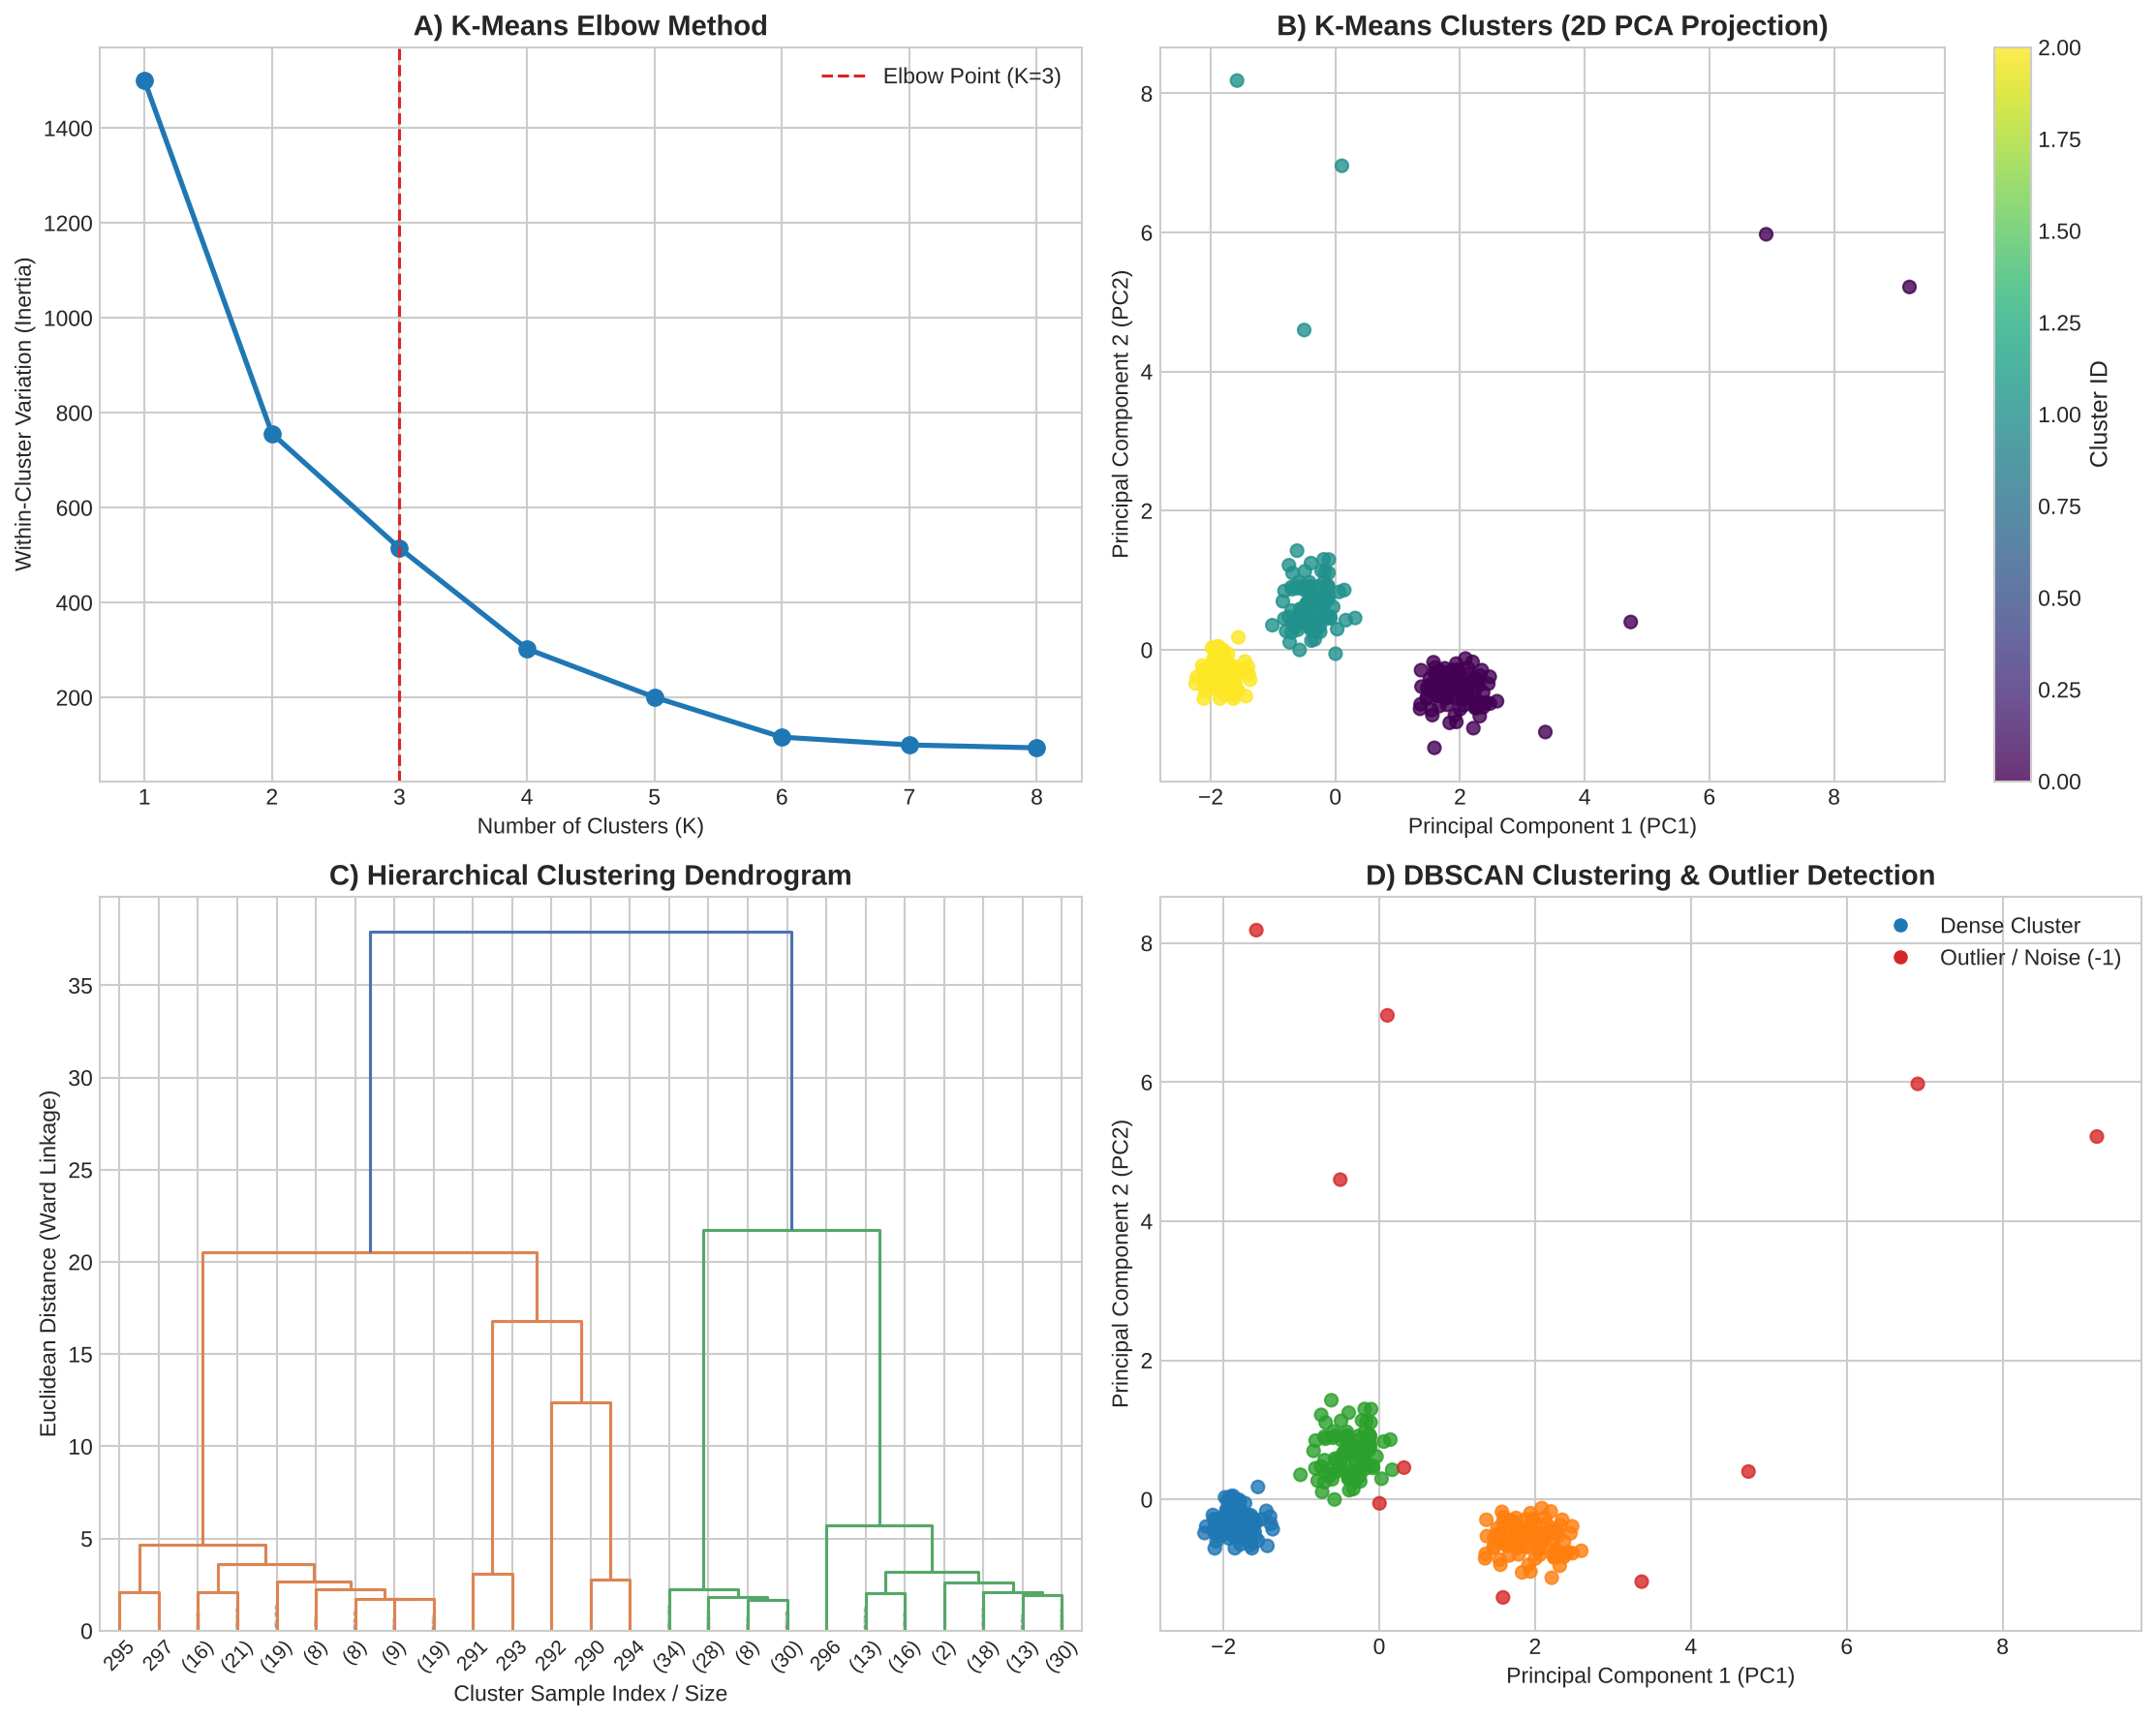

In [13]:
from IPython.display import Image, display
display(Image("unsupervised_learning_master_plot.png"))

---

💼 [LinkedIn](https://www.linkedin.com/in/prajwalskandas) · 💻 [GitHub](https://github.com/prajwalskandas31-sudo) · 🏠 [Course home](https://chipped-willow-4a2.notion.site/AI-Engineering-Course-Tech-with-Prajwal-4056f1ed006e819e88c5c3d15d1b2e0c)